In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (confusion_matrix, roc_curve, auc, precision_recall_curve, 
                             average_precision_score, f1_score, accuracy_score, 
                             matthews_corrcoef, roc_auc_score, precision_score, recall_score)
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import shap
import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

In [24]:
df = pd.read_csv("Thyroid_Diff.csv")
df_viz = df.copy() 
le = LabelEncoder()
for col in df.select_dtypes(include=['object']).columns:
    df[col] = le.fit_transform(df[col])
X = df.drop("Recurred", axis=1)
y = df["Recurred"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [26]:
models = {
    "Logistic Reg": LogisticRegression(max_iter=1000),
    "SVM": SVC(probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', verbose=0, random_state=42),
    "LightGBM": LGBMClassifier(verbose=-1, random_state=42),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=42)
}
results = []
trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    f1 = f1_score(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    mcc = matthews_corrcoef(y_test, y_pred)
    roc = roc_auc_score(y_test, y_prob)
    results.append({
        "Model": name, 
        "F1 Score": f1, 
        "Accuracy": acc, 
        "Precision": prec, 
        "Recall": rec,
        "MCC": mcc, 
        "ROC AUC": roc
    })
    trained_models[name] = model
results_df = pd.DataFrame(results).set_index("Model").sort_values(by="F1 Score", ascending=False)
best_model_name = results_df.index[0] # En iyi model
best_model = trained_models[best_model_name]

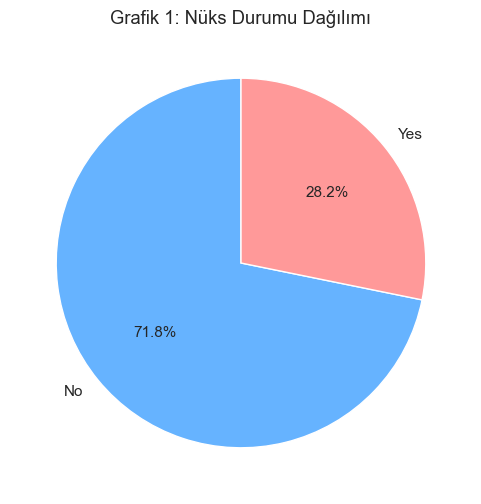

In [27]:
# Grafik 1: Nüks Durumu
plt.figure(figsize=(6, 6))
counts = df_viz['Recurred'].value_counts()
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90, colors=['#66b3ff', '#ff9999'])
plt.title('Grafik 1: Nüks Durumu Dağılımı')
plt.show()

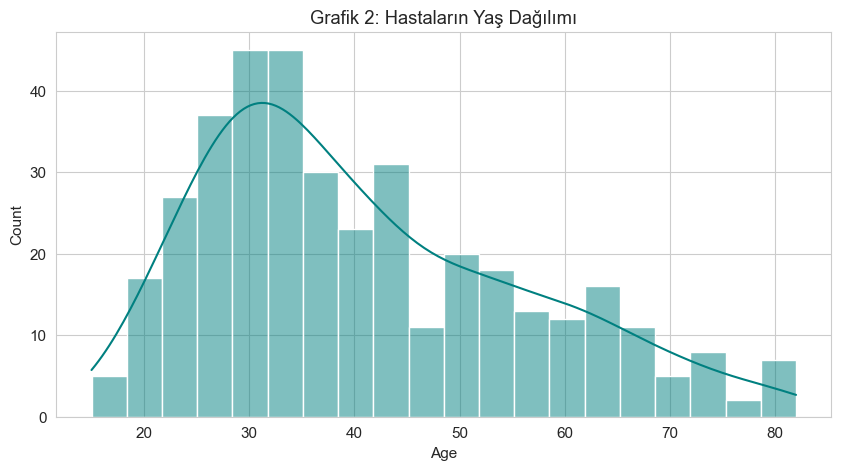

In [28]:
# Grafik 2: Yaş Dağılımı
plt.figure(figsize=(10, 5))
sns.histplot(df_viz['Age'], kde=True, bins=20, color='teal')
plt.title('Grafik 2: Hastaların Yaş Dağılımı')
plt.show()

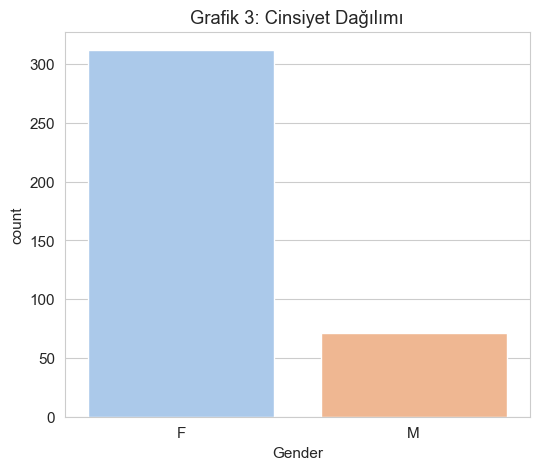

In [29]:
# Grafik 3: Cinsiyet
plt.figure(figsize=(6, 5))
sns.countplot(x='Gender', data=df_viz, palette='pastel')
plt.title('Grafik 3: Cinsiyet Dağılımı')
plt.show()

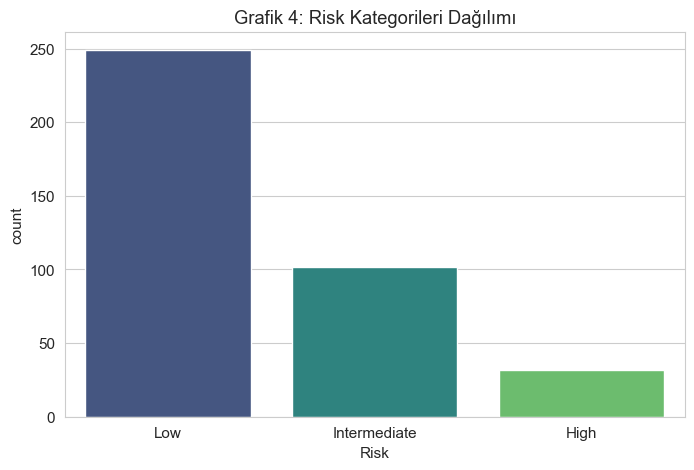

In [30]:
# Grafik 4: Risk Kategorileri
plt.figure(figsize=(8, 5))
sns.countplot(x='Risk', data=df_viz, order=['Low', 'Intermediate', 'High'], palette='viridis')
plt.title('Grafik 4: Risk Kategorileri Dağılımı')
plt.show()

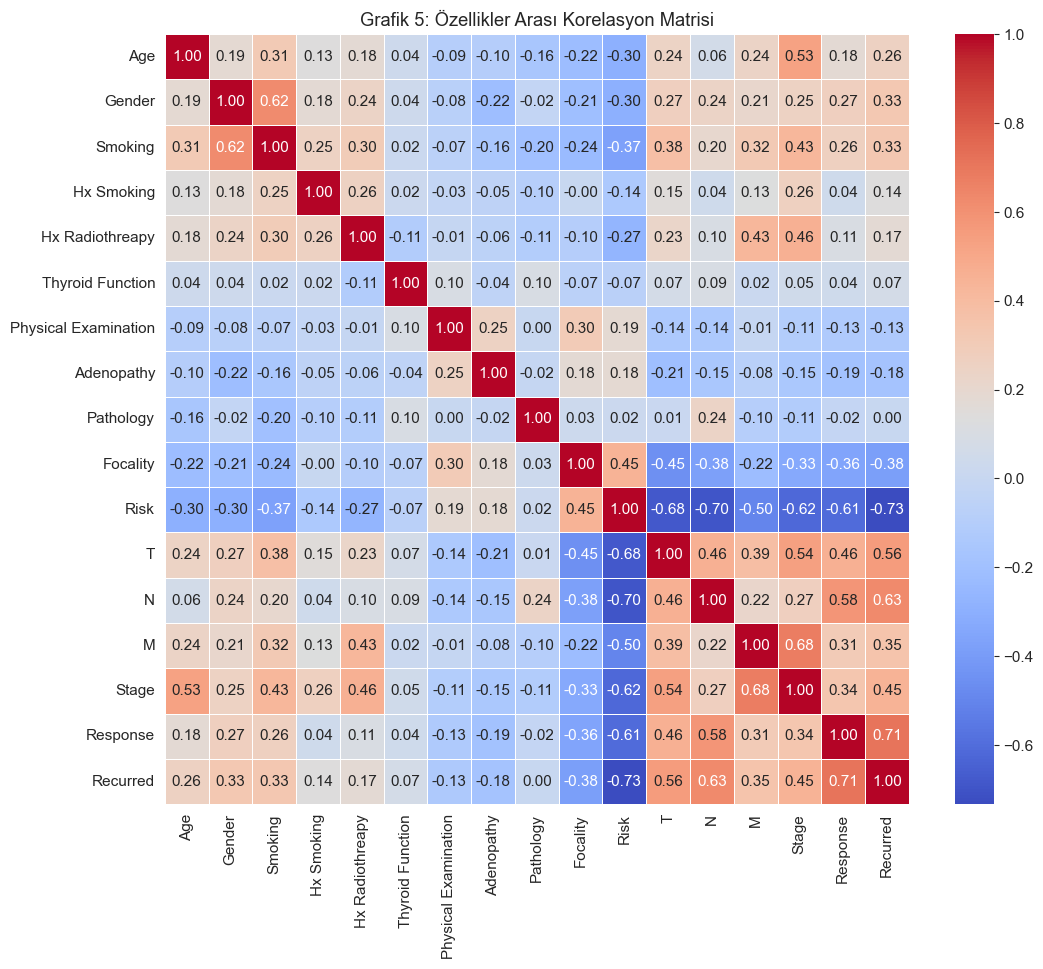

In [31]:
# Grafik 5: Korelasyon Matrisi
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Grafik 5: Özellikler Arası Korelasyon Matrisi')
plt.show()

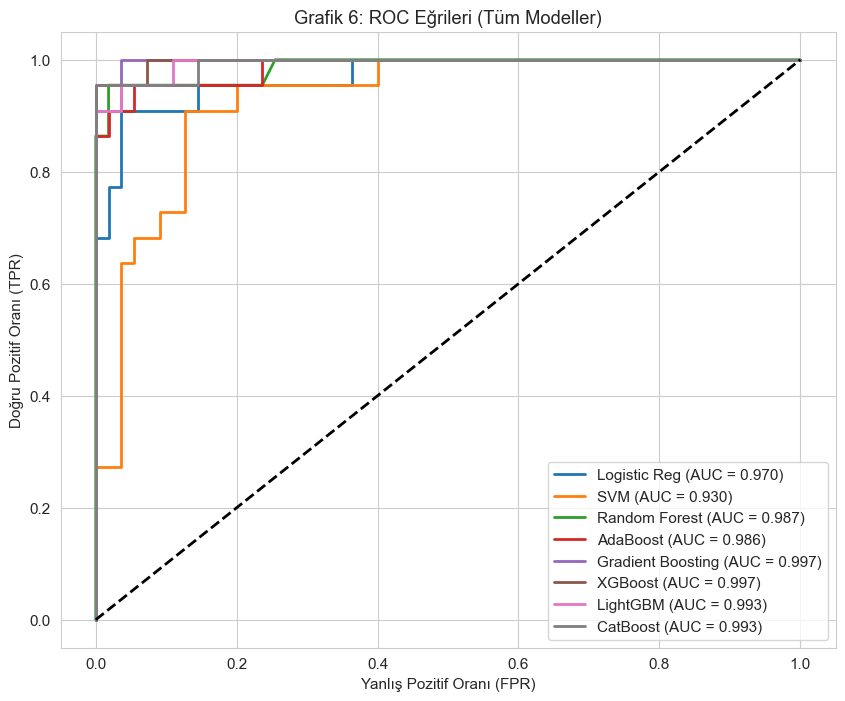

In [32]:
# Grafik 6: Tüm Modellerin ROC Eğrileri
plt.figure(figsize=(10, 8))
for name, model in trained_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_val = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_val:.3f})')
plt.plot([0, 1], [0, 1], color='black', linestyle='--', lw=2)
plt.xlabel('Yanlış Pozitif Oranı (FPR)')
plt.ylabel('Doğru Pozitif Oranı (TPR)')
plt.title('Grafik 6: ROC Eğrileri (Tüm Modeller)')
plt.legend(loc="lower right")
plt.show()

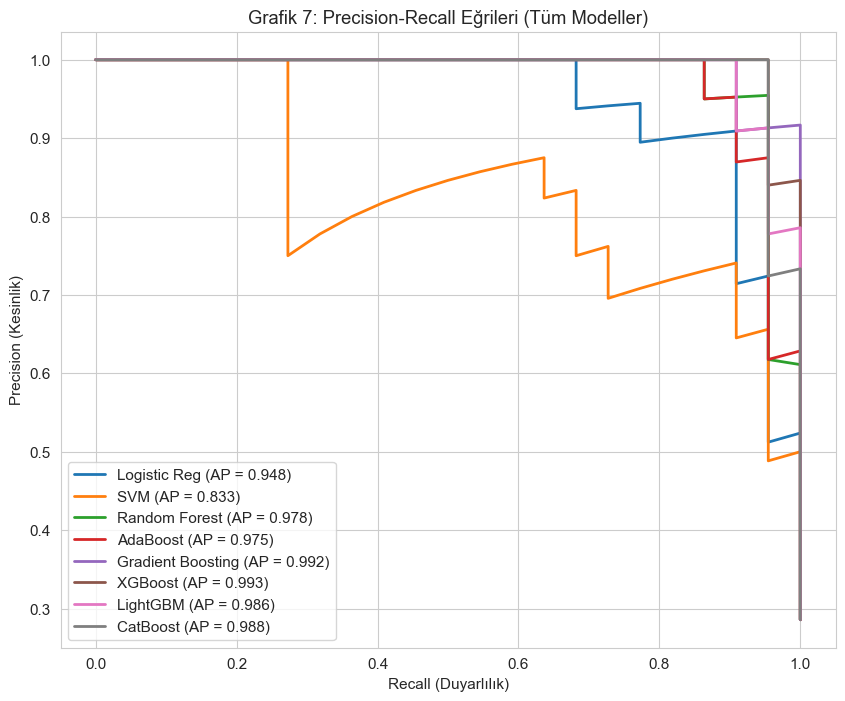

In [33]:
# Grafik 7: Tüm Modellerin Precision-Recall Eğrileri
plt.figure(figsize=(10, 8))
for name, model in trained_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    plt.plot(recall, precision, lw=2, label=f'{name} (AP = {ap:.3f})')
plt.xlabel('Recall (Duyarlılık)')
plt.ylabel('Precision (Kesinlik)')
plt.title('Grafik 7: Precision-Recall Eğrileri (Tüm Modeller)')
plt.legend(loc="lower left")
plt.show()

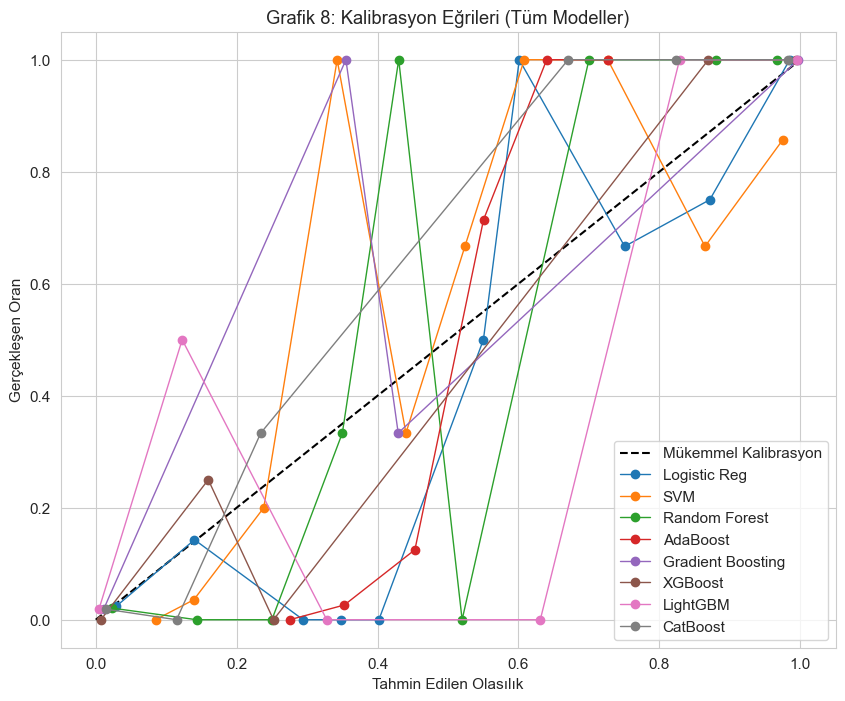

In [34]:
# Grafik 8: Tüm Modellerin Kalibrasyon Eğrileri
plt.figure(figsize=(10, 8))
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Mükemmel Kalibrasyon')
for name, model in trained_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)
    plt.plot(prob_pred, prob_true, marker='o', lw=1, label=name)
plt.xlabel('Tahmin Edilen Olasılık')
plt.ylabel('Gerçekleşen Oran')
plt.title('Grafik 8: Kalibrasyon Eğrileri (Tüm Modeller)')
plt.legend(loc="best")
plt.show()

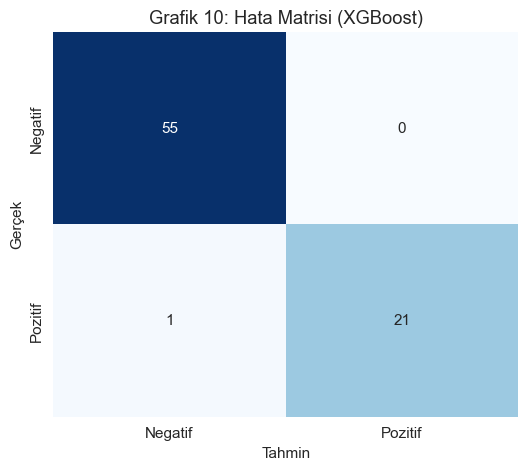

In [35]:
# Grafik 10: Hata Matrisi
y_pred_best = best_model.predict(X_test)
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Negatif', 'Pozitif'], yticklabels=['Negatif', 'Pozitif'])
plt.title(f'Grafik 10: Hata Matrisi ({best_model_name})')
plt.ylabel('Gerçek')
plt.xlabel('Tahmin')
plt.show()

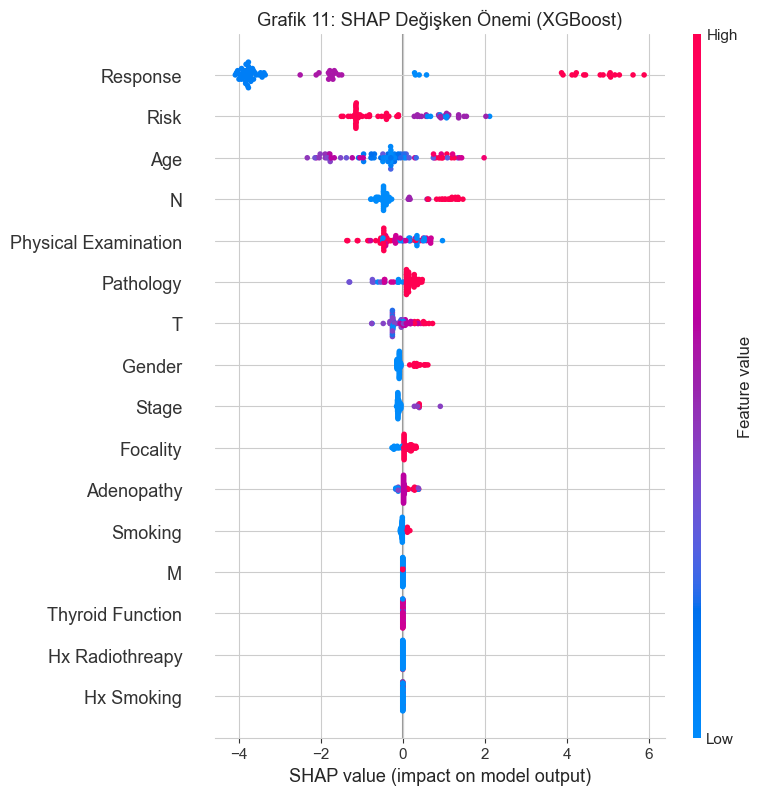

In [37]:
# Grafik 11: SHAP Summary Plot (Sadece En İyi Model)
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, show=False)
plt.title(f'Grafik 11: SHAP Değişken Önemi ({best_model_name})')
plt.show()

In [38]:
print("\n=== MODEL PERFORMANS SKOR TABLOSU ===")
print(results_df.to_string())


=== MODEL PERFORMANS SKOR TABLOSU ===
                   F1 Score  Accuracy  Precision    Recall       MCC   ROC AUC
Model                                                                         
XGBoost            0.976744  0.987013   1.000000  0.954545  0.968246  0.996694
CatBoost           0.952381  0.974026   1.000000  0.909091  0.936586  0.993388
LightGBM           0.930233  0.961039   0.952381  0.909091  0.903696  0.993388
Gradient Boosting  0.926829  0.961039   1.000000  0.863636  0.904967  0.996694
AdaBoost           0.909091  0.948052   0.909091  0.909091  0.872727  0.985950
Random Forest      0.904762  0.948052   0.950000  0.863636  0.871025  0.987190
Logistic Reg       0.869565  0.922078   0.833333  0.909091  0.815726  0.970248
SVM                0.400000  0.766234   0.750000  0.272727  0.349948  0.929752
